In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage

In [9]:
# Generate synthetic dataset

X, y = make_blobs(
    n_samples=100,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

print("Dataset Shape:", X.shape)

print("\nFirst 5 Data Points:")
print(X[:5])

Dataset Shape: (100, 2)

First 5 Data Points:
[[-8.14981777 -9.15238043]
 [ 5.86015466  0.12687321]
 [-3.2134092   9.82812619]
 [ 6.7440703  -0.12960691]
 [-6.34294615 -6.0389328 ]]


In [11]:
print("----- K-Means Clustering -----")

# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train model
kmeans.fit(X)

# Get cluster labels
kmeans_labels = kmeans.labels_

# Get cluster centers
centers = kmeans.cluster_centers_

print("Cluster Labels:")
print(kmeans_labels)

print("\nCluster Centers:")
print(centers)

----- K-Means Clustering -----
Cluster Labels:
[1 2 0 2 1 2 0 2 2 0 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 2 1 1 1 1 2 2 1 0 0 0
 0 2 2 1 0 2 0 0 2 1 1 1 2 2 2 0 1 1 1 0 0 2 0 1 2 1 2 1 1 2 1 2 2 2 1 1 0
 2 1 2 1 2 2 0 2 0 1 0 0 0 2 0 2 2 2 0 2 0 0 0 2 1 0]

Cluster Centers:
[[-2.74710707  8.89649797]
 [-6.98775083 -6.57427024]
 [ 4.42932559  1.92179535]]


C:\Users\rlsgi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


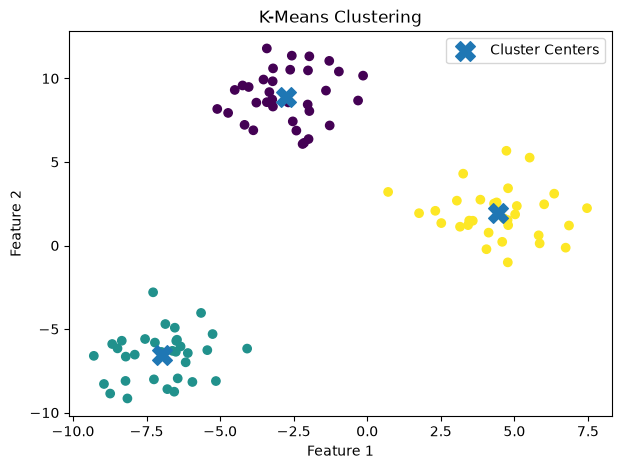

In [12]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

In [13]:
print("----- Hierarchical Clustering -----")

# Create linkage matrix
linked = linkage(X, method='ward')

print("Linkage Matrix Shape:", linked.shape)

----- Hierarchical Clustering -----
Linkage Matrix Shape: (99, 4)


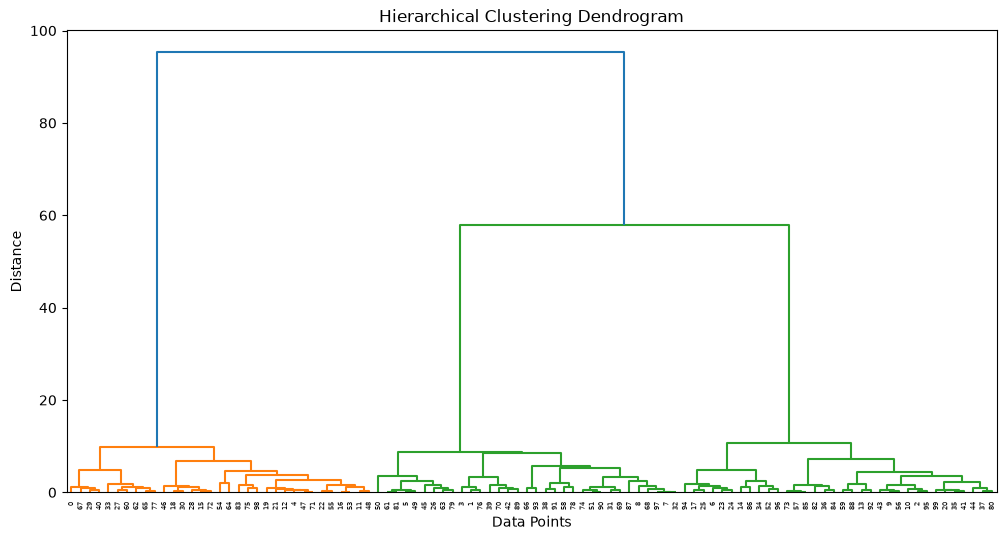

In [14]:
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()